# KEGG ORA pathways (fig1b) — pathway score vs TMB correlations

Two bootstrap strategies (same observed global Pearson r; CIs differ):

1. **Cancer-type bootstrap** (`bs_cancer_type`) — resample cancer types with replacement, pool samples, recompute r (fig1d).
2. **Within-cancer bootstrap** (`bs_within_cancer`) — resample patients within each cancer type, pool, recompute r (fig1c).

Outputs:
- `results/figures/main/fig1/fig1b_kegg_ora_pathway_tmb_corr_bs_cancer_type.pdf`
- `results/figures/main/fig1/fig1b_kegg_ora_pathway_tmb_corr_bs_within_cancer.pdf`

In [1]:
import socket, os, sys

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser(
        "~/Documents/research/scg/protein-master/v2_pancan_batch_corrected"
    )

OUT_DIR = f"{BASE_DIR}/results/figures/main/fig1"
os.makedirs(OUT_DIR, exist_ok=True)
sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import FIG1B_KEGG_GROUP_COLORS, FIG1B_KEGG_GROUP_ORDER

In [2]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

In [3]:
corr_cancer_type = pd.read_csv(
    f"{BASE_DIR}/analysis/03_complex/corr_kegg_ora_pathway_vs_tmb_bs_cancer_type.csv"
)
corr_within_cancer = pd.read_csv(
    f"{BASE_DIR}/analysis/03_complex/corr_kegg_ora_pathway_vs_tmb_bs_within_cancer.csv"
)

In [4]:
def plot_corr_bars(corr_df, title, subtitle, out_path):
    plot_df = corr_df.copy()
    plot_df["group"] = pd.Categorical(
        plot_df["group"], categories=FIG1B_KEGG_GROUP_ORDER, ordered=True
    )
    plot_df = plot_df.sort_values(["group", "r"], ascending=[True, True])

    fig, ax = plt.subplots(figsize=(10, 12))
    colors = [FIG1B_KEGG_GROUP_COLORS[g] for g in plot_df["group"]]

    ax.barh(plot_df["description"], plot_df["r"], color=colors, height=0.7)
    ax.errorbar(
        plot_df["r"],
        plot_df["description"],
        xerr=[plot_df["r"] - plot_df["ci_low"], plot_df["ci_high"] - plot_df["r"]],
        fmt="none",
        color="black",
        capsize=2,
        linewidth=0.8,
    )
    ax.axvline(0, color="#666666", linestyle="dashed", linewidth=0.6)
    ax.set_xlabel("Pearson r (pathway score vs log10(TMB))")
    ax.set_title(title)
    ax.text(0.01, 1.01, subtitle, transform=ax.transAxes, fontsize=9, va="bottom")

    legend_handles = [
        mpatches.Patch(color=c, label=g)
        for g, c in FIG1B_KEGG_GROUP_COLORS.items()
        if g in set(plot_df["group"])
    ]
    ax.legend(handles=legend_handles, title="Functional category", loc="lower right", fontsize=8)

    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.show()
    print(f"Saved → {out_path}")

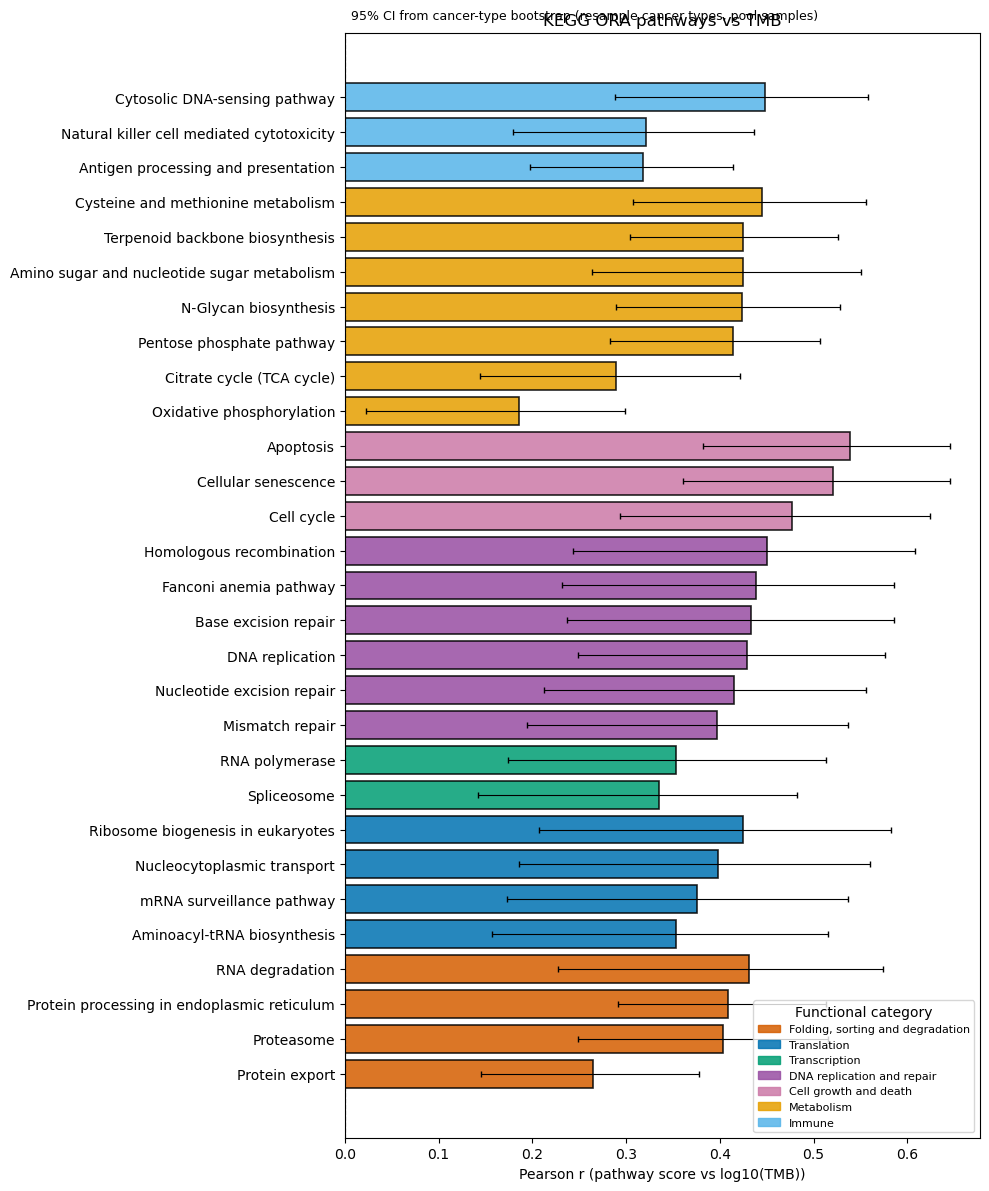

Saved → /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/results/figures/main/fig1/fig1b_kegg_ora_pathway_tmb_corr_bs_cancer_type.pdf


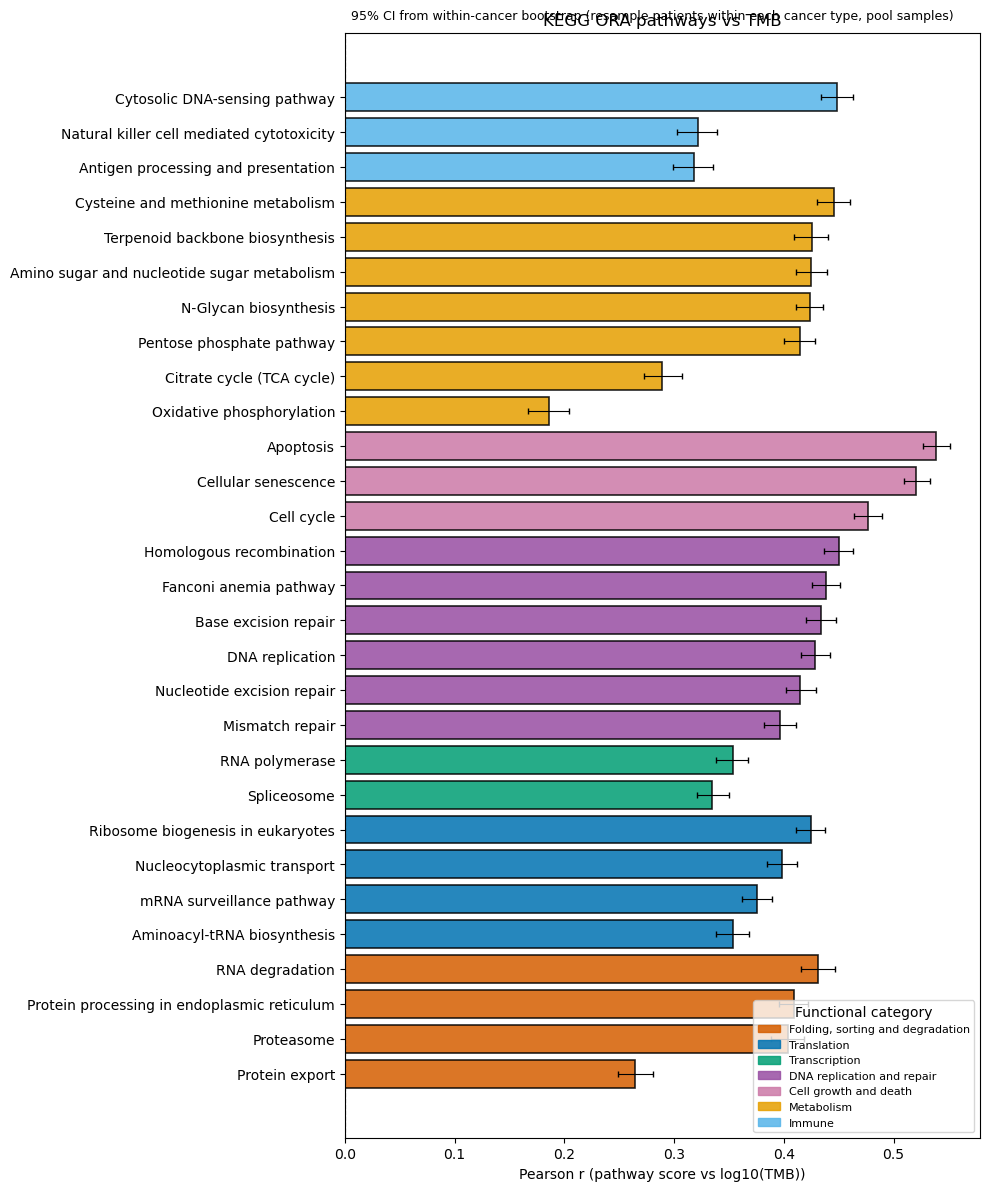

Saved → /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/results/figures/main/fig1/fig1b_kegg_ora_pathway_tmb_corr_bs_within_cancer.pdf


In [5]:
plot_corr_bars(
    corr_cancer_type,
    title="KEGG ORA pathways vs TMB",
    subtitle="95% CI from cancer-type bootstrap (resample cancer types, pool samples)",
    out_path=f"{OUT_DIR}/fig1b_kegg_ora_pathway_tmb_corr_bs_cancer_type.pdf",
)

plot_corr_bars(
    corr_within_cancer,
    title="KEGG ORA pathways vs TMB",
    subtitle="95% CI from within-cancer bootstrap (resample patients within each cancer type, pool samples)",
    out_path=f"{OUT_DIR}/fig1b_kegg_ora_pathway_tmb_corr_bs_within_cancer.pdf",
)